# Lost in Translation
## Phase I: language, locale and caption content

**AI-aided pair:** Klaus Niederberger and Markus Brunner.  
**Model:** `google/siglip2-base-patch16-256` · **XM3600:** 3,600 images, captions in 36 languages.

Does matching a caption's language to an image's locale improve retrieval, and what might explain the association? Sections 1 to 7 investigate this question on XM3600. Section 8 brings together the findings.

We later added a separate experiment on portrait retrieval using the same model and a new dataset, FairFace. It follows the original investigation in **Appendix A**.

The [family-versus-culture analysis](supplementary/family_vs_culture_analysis.ipynb) is another supplementary comparison.

[Sources and reproducibility](implementation/README.md#sources-and-reproducibility).


### Measurements

- **Recall@1:** the intended image ranks first among 3,600 candidates. Another image can also fit a generic caption.
- **Mean distractor margin:** cosine similarity to the intended image minus the mean cosine similarity to the other 3,599 images. This margin is not a probability.
- **Hard margin:** cosine similarity to the intended image minus the highest cosine similarity to an incorrect image. A negative value means an incorrect image scores higher.
- **Aggregation:** average captions for each image and language first, then average images. Each image's Recall@1 is the fraction of its captions ranked first. The multilingual overview weights languages equally.
- **Locale:** a dataset sampling label rather than a guaranteed cultural identity. Hindi images were sampled globally and some Persian images use a wider geographic fallback.


In [1]:
from pathlib import Path
import sys

candidates = [Path.cwd(), *Path.cwd().parents]
AI_DIR = next(p for base in candidates for p in [base, base / "phase-1" / "ai-aided"]
              if (p / "implementation" / "config.py").is_file())
if str(AI_DIR) not in sys.path:
    sys.path.insert(0, str(AI_DIR))

import numpy as np
import pandas as pd
from IPython.display import display
from implementation import config
from implementation.analyze import TOPICS
from implementation.notebook_support import (
    load_results, setup_style, show_figure, plot_language_retrieval, plot_heatmap,
    plot_matching_effects, plot_margin_vs_retrieval, plot_translation_pairs,
    plot_translation_effects, image_gallery, retrieval_gallery,
    plot_cue_summary, plot_truncation,
)
setup_style()
pd.set_option("display.max_colwidth", 150)
pd.set_option("display.max_rows", 40)

# Change these to inspect a different cohort or pilot example.
CUE_LANGUAGE = "de"
RETRIEVAL_LANGUAGE = "de"
PILOT_EXAMPLE_ID = "en-de-069"
SEED = 20261111

In [2]:
results = load_results()  # validates model, settings, counts, and translation provenance
queries = results["queries"]
features = results["features"]
effects = results["effects"]
pilot = results["translation_pairs"]
analysis_meta = results["analysis_metadata"]

# This averaging step is explicit: images with more captions do not dominate.
metrics = ["margin", "cosine", "recall_at_1", "recall_at_5", "reciprocal_rank"]
per_image = queries.groupby(["image_key", "locale", "caption_lang"], as_index=False)[metrics].mean()

## 1. How much does retrieval differ between languages?

Recall@1, Recall@5 and reciprocal rank use equal image weights and the same candidate pool. Highlighted languages reappear below.

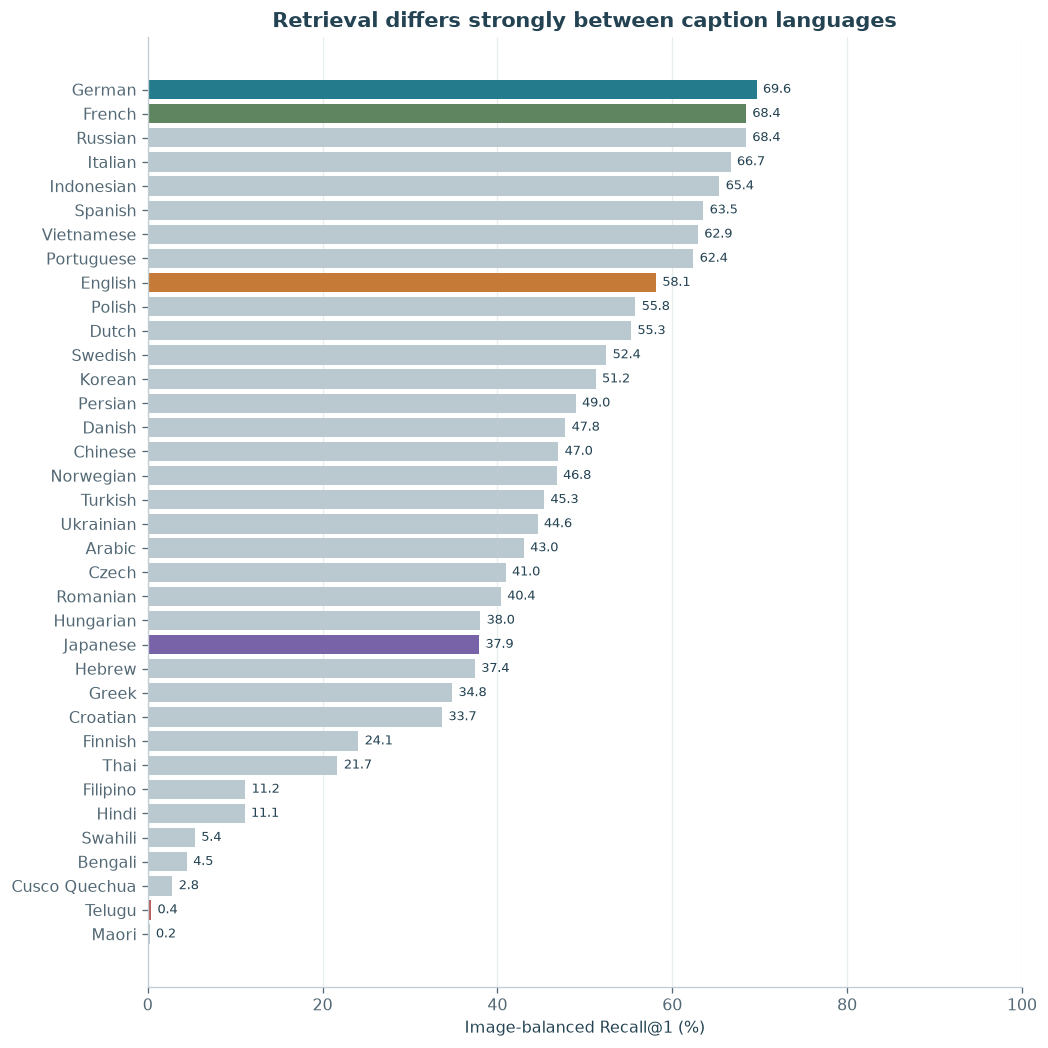

,Recall@1 (%),Recall@5 (%),reciprocal_rank,images
caption_lang,,,,
en,58.14,82.29,0.69,3600
de,69.65,89.67,0.79,3600
ja,37.90,63.50,0.50,3600
te,0.39,1.58,0.01,3600
fr,68.44,89.56,0.78,3600


In [3]:
language_summary = per_image.groupby("caption_lang").agg(
    recall_at_1=("recall_at_1", "mean"),
    recall_at_5=("recall_at_5", "mean"),
    reciprocal_rank=("reciprocal_rank", "mean"),
    images=("image_key", "nunique"),
)
language_summary["Recall@1 (%)"] = 100 * language_summary.recall_at_1
language_summary["Recall@5 (%)"] = 100 * language_summary.recall_at_5
show_figure(plot_language_retrieval(language_summary))
display(language_summary.loc[["en", "de", "ja", "te", "fr"],
    ["Recall@1 (%)", "Recall@5 (%)", "reciprocal_rank", "images"]].round(2))

At Recall@5, Telugu retrieves the intended image in 1.58% of cases, compared with 89.67% for German. The gap persists when retrieval allows five candidates instead of one. These scores alone do not explain its cause.

## 2. Does matching caption language and image locale help?

The margin matrix is rebuilt from caption-level results. Double-centering removes language and locale means. Outlined diagonal cells indicate a match. Positive residuals indicate an above-baseline association, not cultural bias.

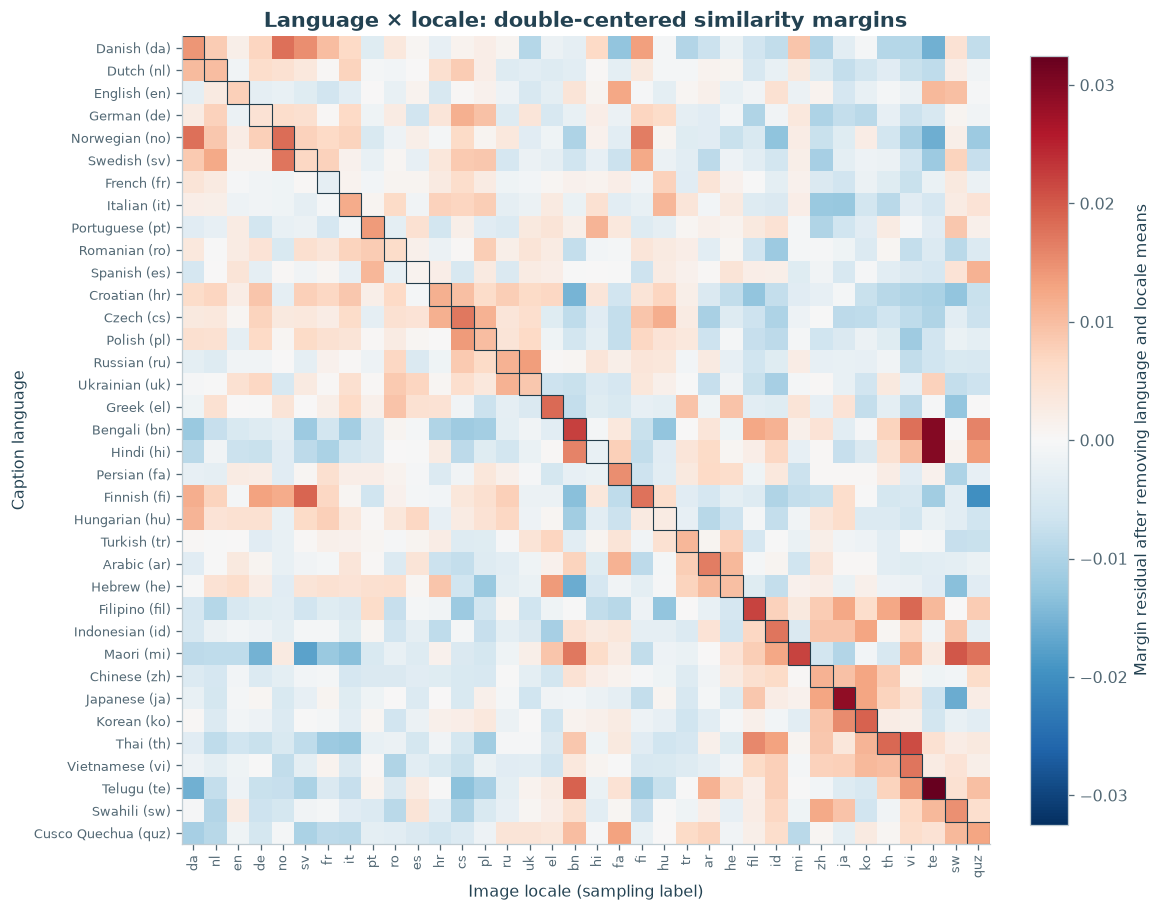

In [4]:
languages = config.active_languages()
margin_matrix = (per_image.groupby(["caption_lang", "locale"]).margin.mean()
                 .unstack("locale").reindex(index=languages, columns=languages))
residual_matrix = (margin_matrix.sub(margin_matrix.mean(axis=1), axis=0)
                   .sub(margin_matrix.mean(axis=0), axis=1) + margin_matrix.to_numpy().mean())

# Confirm that this independently rebuilt matrix agrees with the stored heatmap.
cached = (results["matrices"].query("state == 'double'")
          .pivot(index="caption_lang", columns="locale", values="value")
          .reindex(index=languages, columns=languages))
np.testing.assert_allclose(residual_matrix, cached, atol=1e-6)
show_figure(plot_heatmap(residual_matrix))

### Matching versus other locales

Pointwise 95% intervals use 2,000 bootstrap samples of images drawn within locales. Each sample keeps the captions in all languages for an image together. The global test uses 4,999 shared, two-sided permutations of locale labels with a plus-one correction. All languages use the same shuffle and locale counts are preserved. The global statistic averages language effects.

Image-centering subtracts each image's mean across languages. This accounts for a shared image baseline but leaves differences in caption content unresolved.


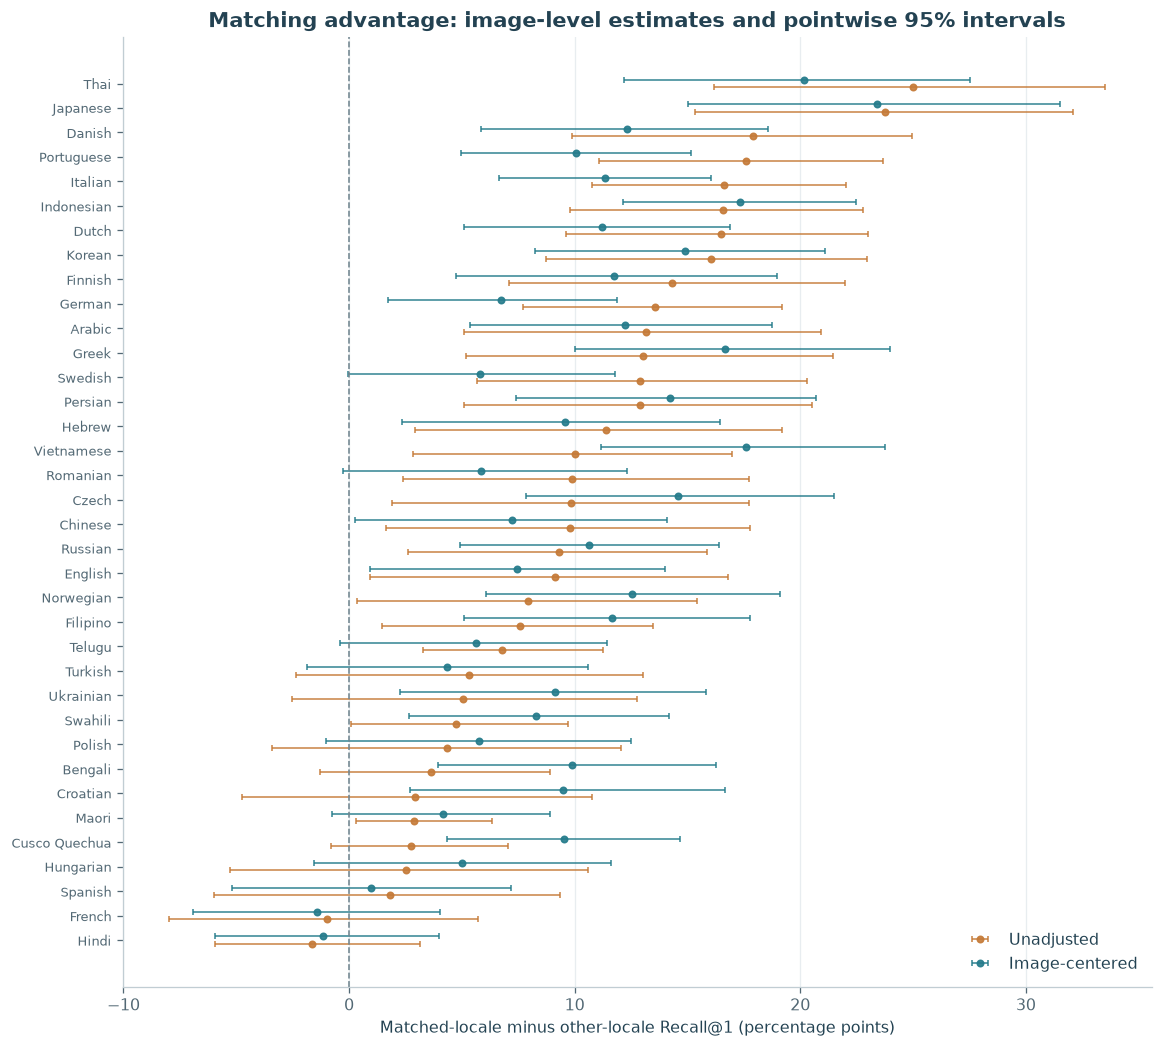

,Matching Recall@1 (%),Other Recall@1 (%),Unadjusted advantage (pp),Image-centered advantage (pp)
Language,,,,
English,67.00,57.89,9.11,7.45
German,82.83,69.27,13.56,6.74
Japanese,61.00,37.24,23.76,23.40
Telugu,7.00,0.20,6.80,5.61
French,67.50,68.46,-0.96,-1.40


In [5]:
raw_r1 = effects.query("subset == 'all' and metric == 'recall_at_1' and view == 'raw'")
centered_r1 = effects.query("subset == 'all' and metric == 'recall_at_1' and view == 'image_centered'")
show_figure(plot_matching_effects(raw_r1, centered_r1))

matching_rows = []
for language in ["en", "de", "ja", "te", "fr"]:
    group = per_image[per_image.caption_lang == language]
    matched = group.locale == language
    matching_rows.append({
        "Language": config.LANGUAGES[language],
        "Matching Recall@1 (%)": 100 * group.loc[matched, "recall_at_1"].mean(),
        "Other Recall@1 (%)": 100 * group.loc[~matched, "recall_at_1"].mean(),
        "Unadjusted advantage (pp)": 100 * raw_r1.set_index("caption_lang").loc[language, "effect"],
        "Image-centered advantage (pp)": 100 * centered_r1.set_index("caption_lang").loc[language, "effect"],
    })
display(pd.DataFrame(matching_rows).set_index("Language").round(2))

The average matching advantage is 9.86 percentage points (global permutation p = 0.0002), but the association differs across languages. German's estimate roughly halves after image-centering, whereas Japanese's barely changes. Shared image difficulty can explain part of the German contrast, not all contrasts between languages. French's interval does not establish a matching benefit.

### Sensitivity to the globally sampled Hindi subset

Exclude images from the Hindi locale and captions in Hindi from inference and centering. Retrieval ranks retain the original candidate pool. In this balanced matrix, image-centering leaves the global mean unchanged by construction.

In [6]:
sensitivity = []
for subset, label in [("all", "All locales / languages"), ("without_hi", "Without Hindi locale / language")]:
    result = analysis_meta["global_tests"][f"{subset}/recall_at_1"]["raw"]
    sensitivity.append({"Subset": label, "Mean matching advantage (pp)": 100 * result["effect"],
                        "Permutation p": result["p"]})
display(pd.DataFrame(sensitivity).set_index("Subset").round(4))

,Mean matching advantage (pp),Permutation p
Subset,,
All locales / languages,9.8574,0.0002
Without Hindi locale / language,10.1811,0.0002


Excluding Hindi barely changes the estimate. The permutation test assumes exchangeable locale labels. Caption content, annotation style and image selection remain competing explanations rather than a causal language effect.

## 3. Does a large matching advantage imply good retrieval?

Compare the difference in margin between matching and other locales with overall Recall@1. They have different units and capture relative association and absolute retrieval, respectively.

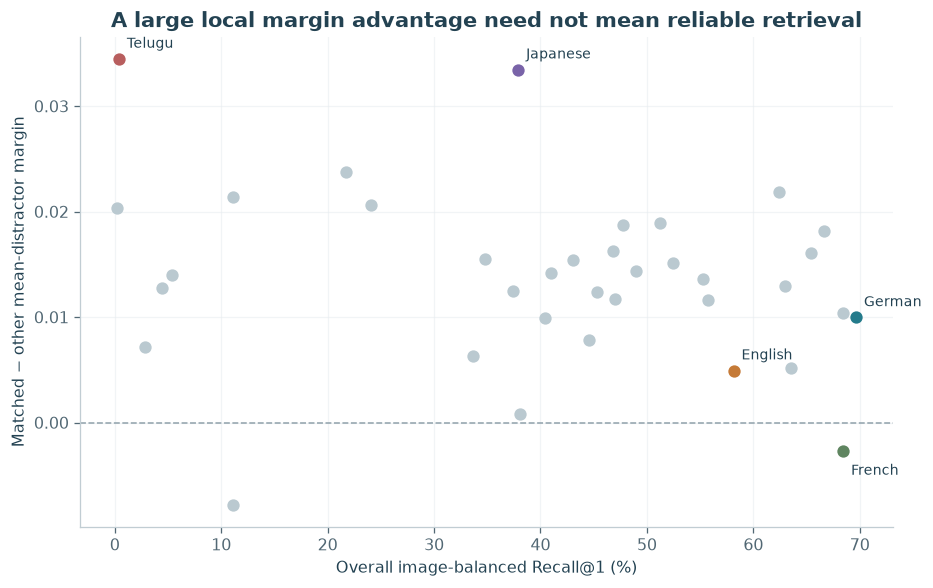

In [7]:
raw_margin = effects.query("subset == 'all' and metric == 'margin' and view == 'raw'").set_index("caption_lang")
comparison = pd.DataFrame({
    "Overall Recall@1 (%)": language_summary["Recall@1 (%)"],
    "Matching margin difference": raw_margin.effect,
})
show_figure(plot_margin_vs_retrieval(comparison))


Telugu's large positive margin difference coexists with 0.39% overall Recall@1: a relative matching advantage does not imply reliable retrieval. The heatmap alone cannot establish retrieval quality.

## 4. Translation control: language or descriptive content?

Select 36 images from the English locale and 36 from the German locale before inspecting scores. For each image compare its first English caption (A), an AI-generated German translation (B), and the average of independent German captions (C). All use the same model and 3,600 candidates.

- **B − A:** changes language while approximately holding content fixed.
- **C − B:** changes description and style within German.

Paired pointwise 95% intervals use 2,000 image resamples within locales. Translations await independent review. The pilot covers two languages/locales, and compares one English caption with an average of German captions.

,,Image pairs
locale,review_status,
de,ai_generated,36
en,ai_generated,36


,Mean margin,Image-balanced Recall@1 (%)
Description,,
Original English source,0.1697,70.8333
German translation of the English source,0.1577,61.1111
Independent German descriptions,0.1865,73.3796


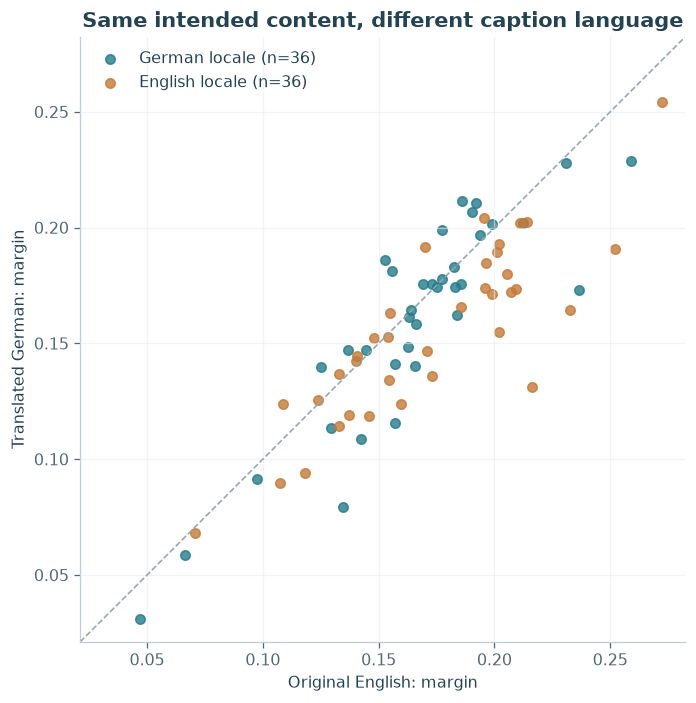

In [8]:
display(pilot.groupby(["locale", "review_status"]).size().rename("Image pairs").to_frame())
conditions = pd.DataFrame({
    "Description": ["Original English source", "German translation of the English source", "Independent German descriptions"],
    "Mean margin": [pilot.source_margin.mean(), pilot.translated_margin.mean(), pilot.human_target_margin.mean()],
    "Image-balanced Recall@1 (%)": 100 * np.array([
        pilot.source_recall_at_1.mean(), pilot.translated_recall_at_1.mean(), pilot.human_target_recall_at_1.mean()]),
})
display(conditions.set_index("Description").round(4))
show_figure(plot_translation_pairs(pilot))

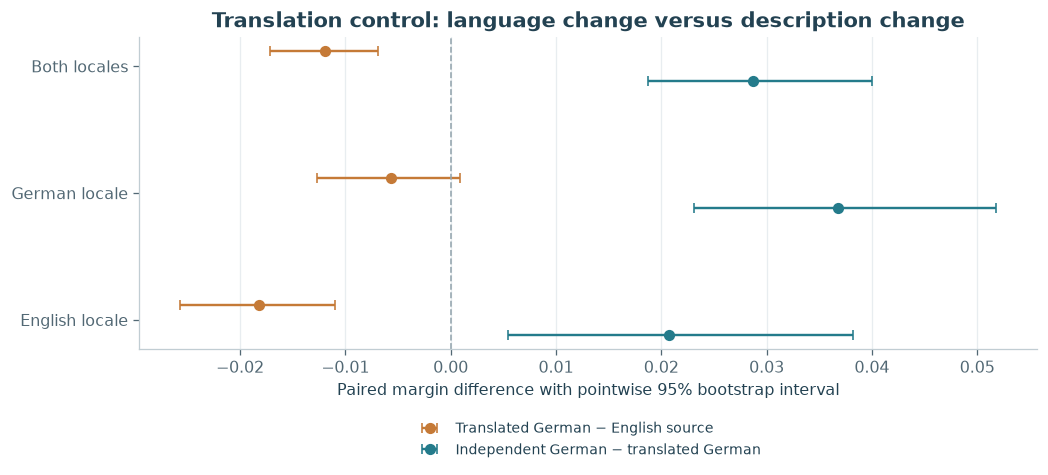

In [9]:
pilot_effects = results["translation_effects"]
show_figure(plot_translation_effects(pilot_effects))


The independent-versus-translated German contrast is positive in both locales. The translation-versus-source interval crosses zero for German-locale images but not English-locale images. Content, writing style, caption selection and translation quality all differ between conditions, so we cannot attribute the result to one of them.

### Example: a birthday cake

This case was selected because of a large retrieval difference. It illustrates a possible explanation without showing how common it is.

,Caption,Intended-image rank
Description,,
English source,The cake in a white plate.,48
German translation,Der Kuchen auf einem weißen Teller.,27
Independent German,Eine rosa weiße Torte mit 90 und Blumen steht auf einem Servierwagen vor einem Tisch,1
Independent German,Eine Geburtstagstorte mit der Nummer 90 auf einem plastik Platte.,1


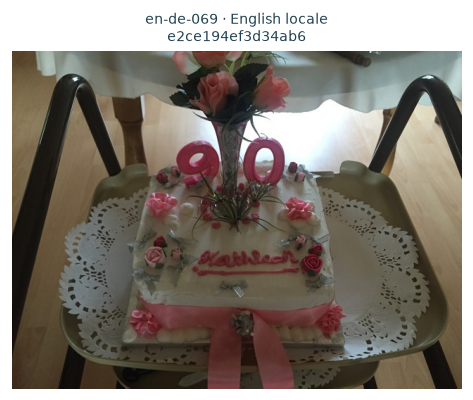

In [10]:
case = pilot.set_index("pair_id").loc[PILOT_EXAMPLE_ID]
native_captions = queries[(queries.image_key == case.image_key) & (queries.caption_lang == case.target_lang)]
caption_rows = [
    {"Description": "English source", "Caption": case.source_text, "Intended-image rank": int(case.source_rank)},
    {"Description": "German translation", "Caption": case.translation, "Intended-image rank": int(case.translated_rank)},
]
caption_rows += [{"Description": "Independent German", "Caption": row.text, "Intended-image rank": row.rank}
                 for row in native_captions.itertuples()]
display(pd.DataFrame(caption_rows).set_index("Description"))
show_figure(image_gallery([case.image_key], [f"{PILOT_EXAMPLE_ID} · {config.LANGUAGES[case.locale]} locale"], columns=1))

The independent captions mention details absent from the source, including the number 90. Those details could improve retrieval, but this selected example cannot isolate their contribution.

## 5. What does SigLIP retrieve when it misses?

Inspect the German query for which an incorrect image leads by the largest margin. This is an extreme case rather than a representative failure. The English captions are independent descriptions of the images, not translations. A fixed random sample follows for further inspection.


,Selected query
Caption ID,96161
Caption language,German
Caption,Aufnahme eines Wohnhauses mit gepflegtem Garten davor.
Intended-image rank,99
Hard margin,-0.116983


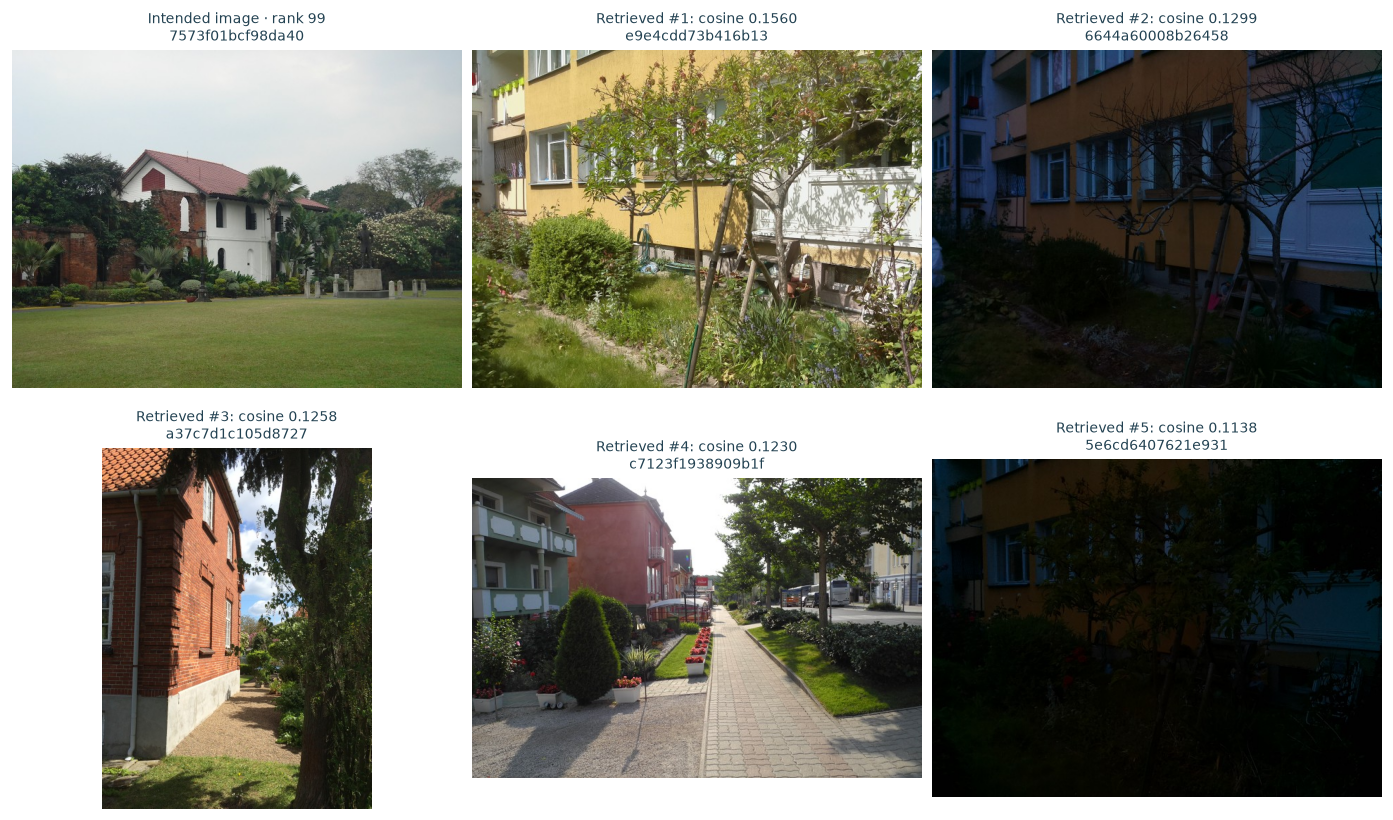

,text,rank,margin
caption_lang,,,
de,Aufnahme eines Wohnhauses mit gepflegtem Garten davor.,99,0.0781
de,Ein weisses Haus mit rotem Ziegelzaun und grosser Rasenfläche mit Palmen umgeben,1,0.2038
en,A beautiful view of the house in the park surrounded by trees under the sky.,22,0.1049
en,A house with a garden beside.,9,0.1033
fil,Bahay na malaki na napapaligiran ng mga puno at istatwa sa labas ng damuhan,14,0.0684
fil,Ang malaking bahay sa isang malaking lote.,72,0.0428


In [11]:
failures = queries[(queries.caption_lang == RETRIEVAL_LANGUAGE) & (queries["rank"] > 1)]
selected_query = failures.sort_values(["hard_margin", "caption_id"]).iloc[0]
QUERY_ID = int(selected_query.caption_id)  # set another caption ID here to inspect it
query = queries.set_index("caption_id").loc[QUERY_ID]
display(pd.Series({
    "Caption ID": QUERY_ID,
    "Caption language": config.LANGUAGES[query.caption_lang],
    "Caption": query.text,
    "Intended-image rank": int(query["rank"]),
    "Hard margin": query.hard_margin,
}, name="Selected query").to_frame())
show_figure(retrieval_gallery(QUERY_ID, results))

same_image = queries[(queries.image_key == query.image_key) & queries.caption_lang.isin(["en", RETRIEVAL_LANGUAGE, query.locale])]
display(same_image[["caption_lang", "text", "rank", "margin"]].set_index("caption_lang").round(4))

### Reproducible random failure sample

Five queries sampled with the fixed seed provide additional cases for inspection.

In [12]:
display(failures.sample(n=min(5, len(failures)), random_state=SEED)[
    ["caption_id", "locale", "text", "rank", "hard_margin"]].set_index("caption_id").round(4))

,locale,text,rank,hard_margin
caption_id,,,,
2877,pt,Nahaufnahme von zwei Brettern auf einer Küchentheke.,13,-0.0196
239777,pl,Frau im Wald auf Wanderung beim Begutachten eines Wanderschildes.,3,-0.0167
230536,uk,Nahaufnahme eines eisernen Kanalisationstores auf Asphaltstraße.,10,-0.0340
170682,hi,"Im Dunkeln sind Neonröhren an einer Metall-Säule in alle Richtungen gekringelt, die hellblau leuchten",2,-0.0024
70068,en,Eine Schlucht ist neben einem Berg in der Wüste zu sehen,15,-0.0337


The intended image ranks 99th for the selected German caption and first for another German caption. Their descriptions differ, which points to a caption-specific problem. A retrieved image can also be a plausible match even when its ID differs from the intended image. The random sample still needs a systematic review of these cases.

## 6. Which caption cues accompany the pattern?

Keywords in the English captions provide provisional cues about the images. The groups can overlap. For the selected language, compare the difference between matching and other locales within each cue, using margins centered by image. The counts show how few images some groups contain. These are descriptive estimates and do not establish causal effects.


,Images,Matching images,Other images,Recall@1 (%),Matching margin difference
Cue,,,,,
Animals,178,9,169,79.9625,0.0091
Vehicles,410,28,382,65.1220,0.0060
Food,314,10,304,74.2569,-0.0015
Buildings,767,9,758,63.1682,0.0318
Nature,1342,26,1316,65.8718,0.0071
People,996,12,984,72.2557,0.0129


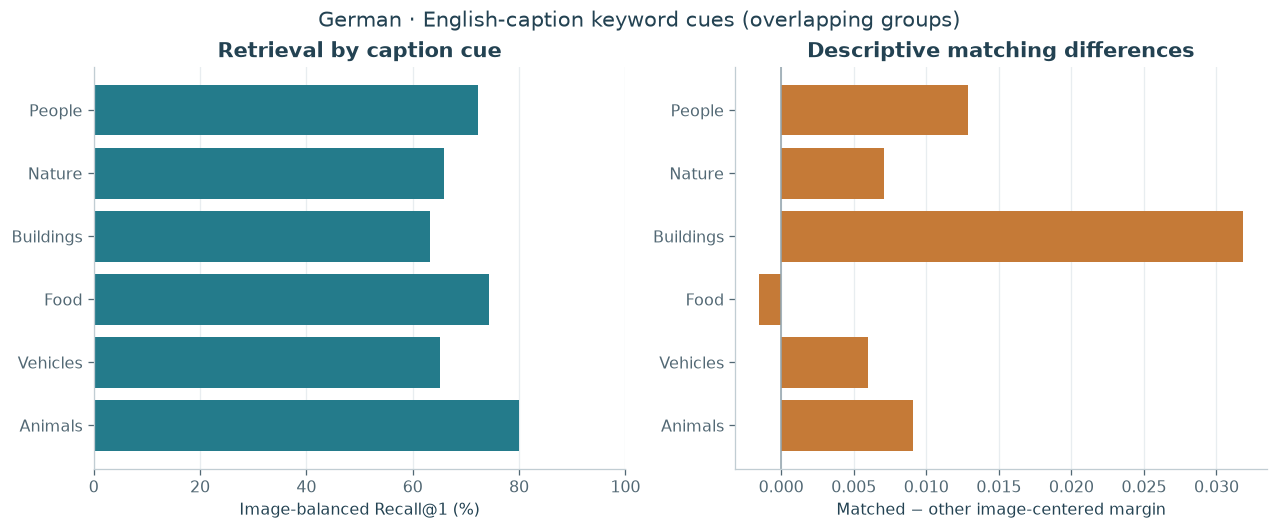

In [13]:
with_cues = queries.merge(features.drop(columns=["image_key", "caption_lang"]), on="caption_id", validate="one_to_one")
image_baseline = per_image.groupby("image_key").margin.mean()
selected = with_cues[with_cues.caption_lang == CUE_LANGUAGE]
cue_rows = []
for cue in TOPICS:
    group = selected[selected[f"topic_{cue}"]]
    image_scores = group.groupby("image_key").agg(locale=("locale", "first"), margin=("margin", "mean"), recall=("recall_at_1", "mean"))
    image_scores["centered"] = image_scores.margin - image_baseline.reindex(image_scores.index)
    matching = image_scores.locale == CUE_LANGUAGE
    if matching.sum() < 3 or (~matching).sum() < 3:
        continue
    cue_rows.append({
        "Cue": cue, "Images": len(image_scores), "Matching images": int(matching.sum()),
        "Other images": int((~matching).sum()), "Recall@1 (%)": 100 * image_scores.recall.mean(),
        "Matching margin difference": image_scores.loc[matching, "centered"].mean() - image_scores.loc[~matching, "centered"].mean(),
    })
cue_summary = pd.DataFrame(cue_rows).set_index("Cue")
display(cue_summary.round(4))
show_figure(plot_cue_summary(cue_summary, CUE_LANGUAGE))

The estimate for buildings rests on only nine images from the matching locale despite its much larger total cohort. Apparent differences between cues could reflect this imbalance, the mix of locales or caption style. Keyword groups can also overlap and miss synonyms or details.

## 7. Could truncation account for weak results?

Count tokens before the 64-token limit using the pinned tokenizer, inference lowercasing and special tokens.

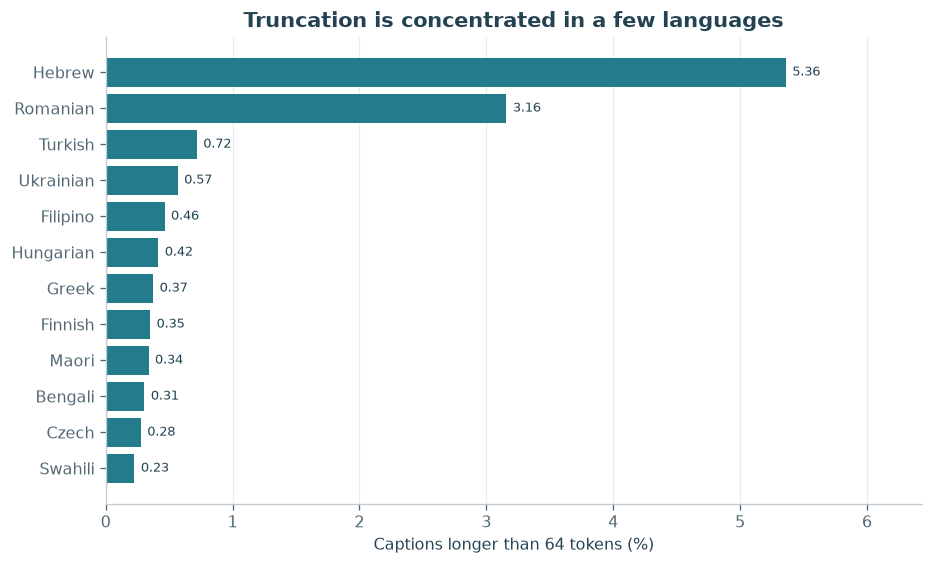

In [14]:
if "truncated" in features:
    truncation = features.groupby("caption_lang").agg(
        Captions=("caption_id", "size"), Truncated=("truncated", "sum"),
        Mean_tokens=("tokens", "mean"), Max_tokens=("tokens", "max"))
    truncation["Truncated (%)"] = 100 * truncation.Truncated / truncation.Captions
    show_figure(plot_truncation(truncation))
else:
    print("Token diagnostics unavailable (--skip-tokenizer).")

Only 0.36% of all captions exceed the limit, so truncation alone is unlikely to explain the broad multilingual gap. The aggregate does not rule out a meaningful effect in affected languages. A controlled shortening experiment would be needed to separate length from content.

## 8. Findings from XM3600 and next questions

Matching language and locale is associated with better retrieval on average. For the margin metric, 34 of 36 unadjusted language effects are positive. Their mean is +0.0137 (global permutation p = 0.0002). The positive signs do not establish significance for every language. Image-centering changes some language-specific estimates, and differences in image selection and caption content remain possible explanations.

A large relative matching margin can coexist with poor absolute retrieval, as Telugu shows. Captions in the same language can also retrieve the same image very differently. The translation pilot points to descriptive content and style as possible contributors, alongside translation quality and caption selection.

The next steps for this investigation are to review the English-to-German translations, classify a representative sample of retrieval errors, and test caption specificity. Phase II can then examine which image regions support a verified behavior.

The FairFace extension below asks a different question about query language and portrait retrieval.


## Appendix A. Additional experiment: FairFace portrait retrieval

After the XM3600 investigation, we added a separate question: does changing the language of a neutral person query change which demographic groups appear near the top of the results? This extension uses the same SigLIP 2 checkpoint with a new dataset and candidate pool. The findings about language and locale in Sections 1 to 8 come from XM3600.

### Candidate pool and queries

Every language searches the same 448 FairFace validation portraits: 16 per combination of seven race annotations, two gender annotations and two adult age bands (20–29, 30–39). Each race group has 64 candidates (14.29%). Selection occurred before scoring.

Five neutral prompt families are used in English, German, French, Spanish, Japanese and Swahili. Four object controls per language test whether the model separates person prompts from object prompts. There are 54 queries in total. All prompts fit the 64-token limit. The AI-generated translations await independent fluent-speaker review. No prompt names a demographic group. One says “adult,” which describes the entire pool.

Race, gender and age are FairFace annotations. The audit describes retrieval within this pool. The labels do not measure identity or skin tone.


In [15]:
from implementation.bias_audit import load_results as load_bias_results
from implementation.bias_plots import (
    plot_exposure, plot_stability, top_one_table, portrait_gallery, plot_sanity,
)
bias = load_bias_results()  # rejects stale prompt/review/candidate hashes
BIAS_FAMILY = "person_photo"
BIAS_DEPTH = 10

display(bias["queries"].query("family == @BIAS_FAMILY")[["language", "text", "review_status", "tokens"]].set_index("language"))

,text,review_status,tokens
language,,,
en,A photo of a person.,source_original,7
de,Ein Foto einer Person.,ai_generated,6
fr,Une photo d’une personne.,ai_generated,8
es,Una foto de una persona.,ai_generated,7
ja,一人の人物の写真。,ai_generated,6
sw,Picha ya mtu.,ai_generated,6


### Representation versus availability

Average top-k group shares over five prompt families. Excess is the share minus the group's pool share. The second heatmap instead subtracts the paired English share. The 50 top-10 ranking slots can repeat portraits and are not 50 independent people.

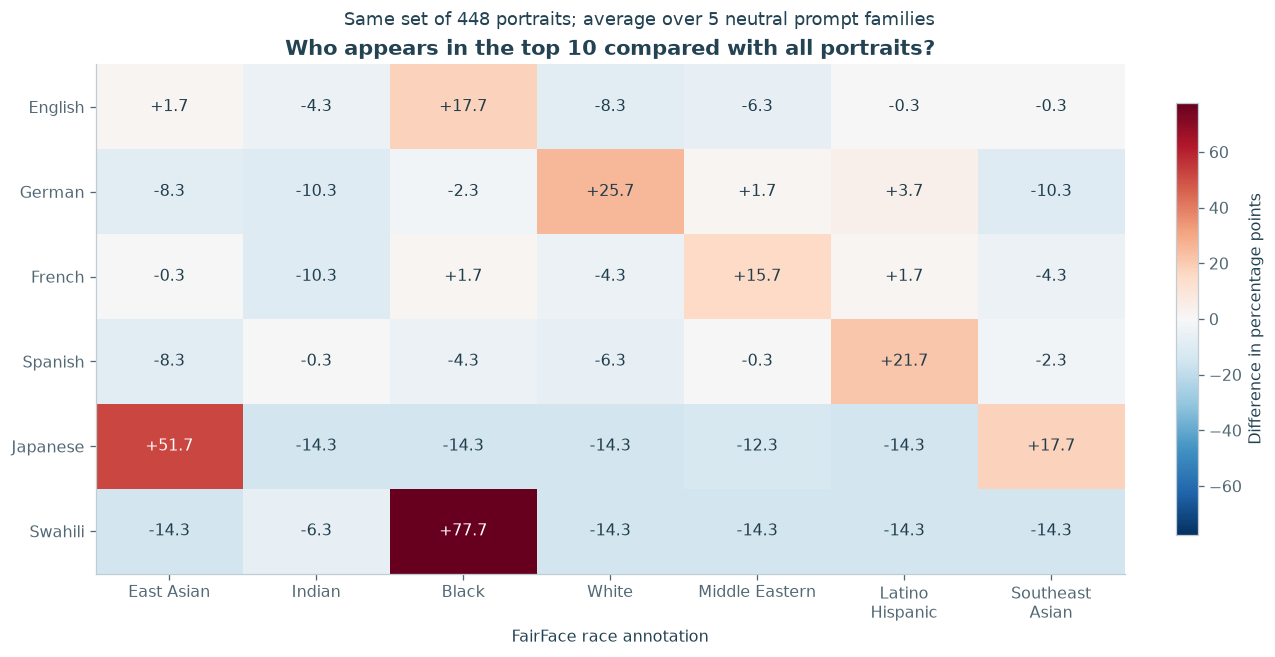

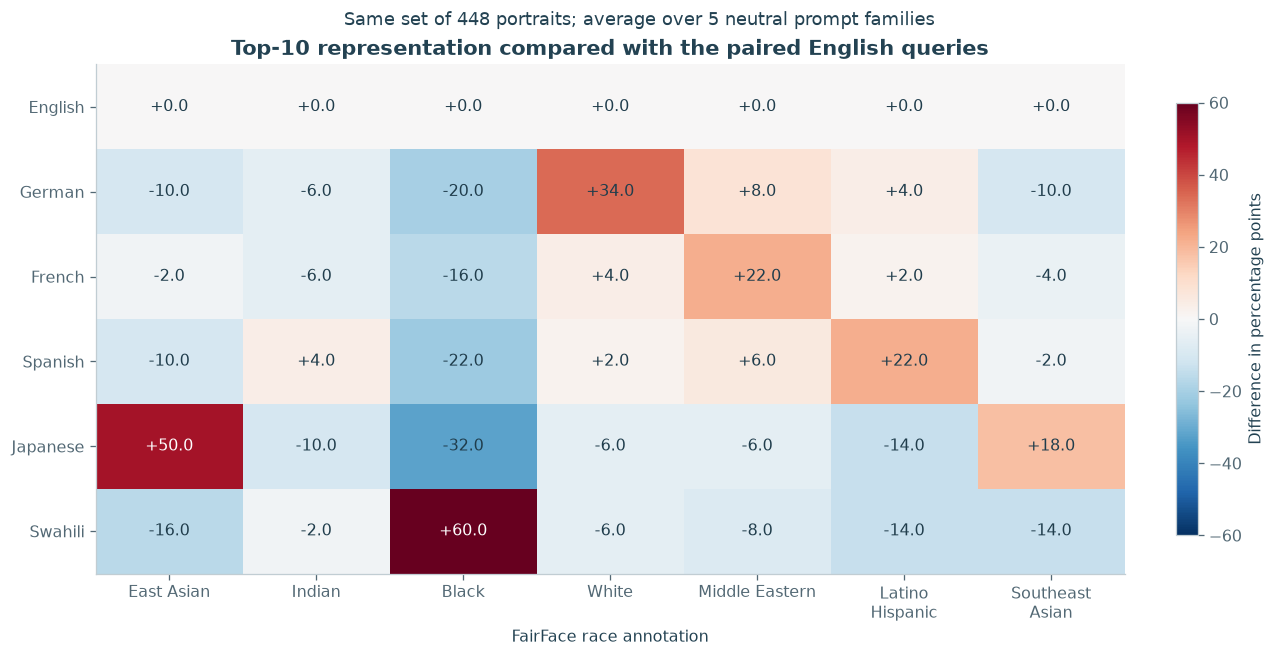

In [16]:
show_figure(plot_exposure(bias, axis="race", k=BIAS_DEPTH, reference="pool"))
show_figure(plot_exposure(bias, axis="race", k=BIAS_DEPTH, reference="english"))

### Stability and ranking depth

Repeat the comparison on 500 shared, balanced subsets of 336 portraits (12 per original stratum). Lines show the central 95% range across subsets: sensitivity to this pool, not population confidence intervals or significance tests. Prompt families stay fixed. Top-50 results check whether concentration persists deeper in the rankings.

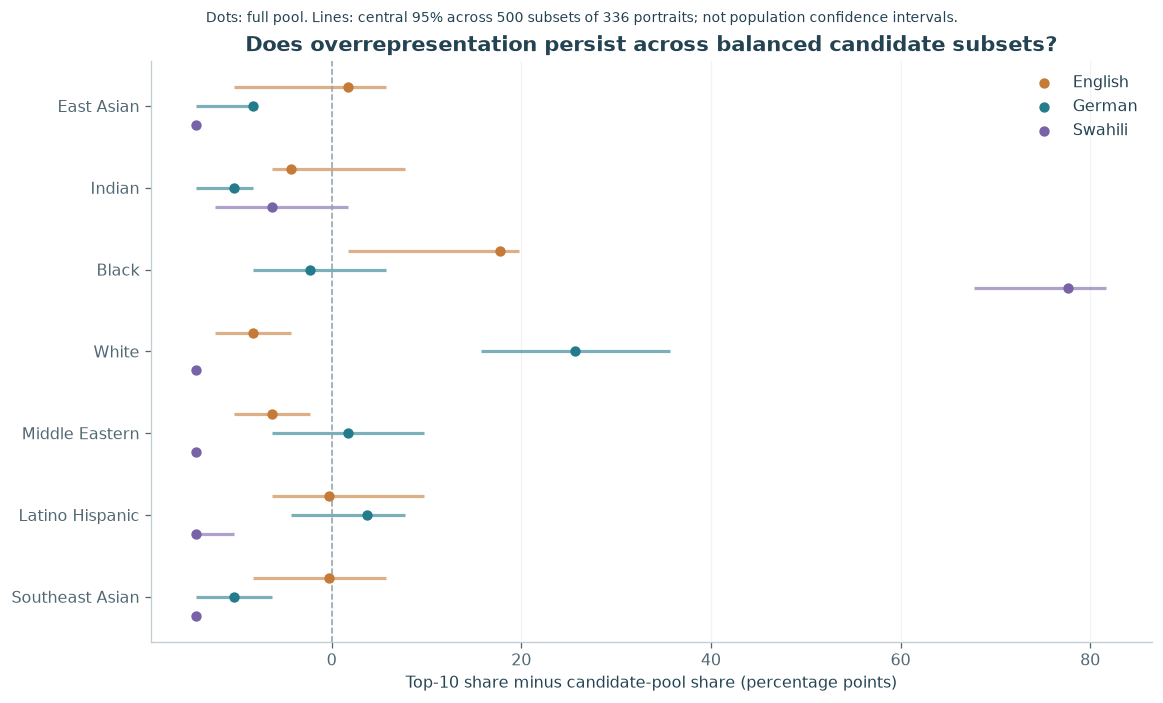

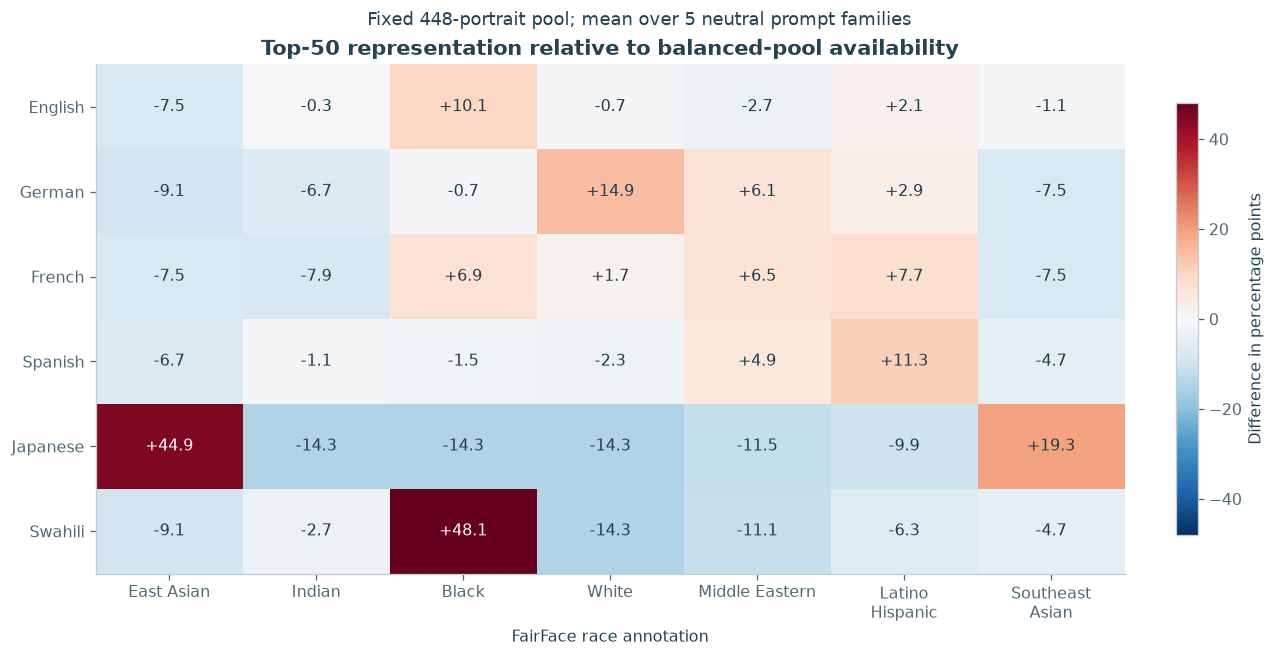

group,Female,Male
language,,
de,52.0,48.0
en,62.0,38.0
es,58.0,42.0
fr,64.0,36.0
ja,36.0,64.0
sw,56.0,44.0


In [17]:
show_figure(plot_stability(bias, axis="race", k=BIAS_DEPTH))
show_figure(plot_exposure(bias, axis="race", k=50))
gender_exposure = bias["exposure"].query("axis == 'gender' and k == @BIAS_DEPTH")
display((100 * gender_exposure.pivot(index="language", columns="group", values="share")).round(1))

### Which portraits rank first?

The gallery uses one query family and FairFace's supplied annotations. Individual winners illustrate the rankings. The exposure comparisons summarize all five prompt families.

,Query,Dataset race label,Dataset gender label,Dataset age band,Image ID,Cosine
Language,,,,,,
English,A photo of a person.,East Asian,Female,30-39,ff-val-02716,0.1299
German,Ein Foto einer Person.,White,Male,30-39,ff-val-10689,0.1381
French,Une photo d’une personne.,East Asian,Female,30-39,ff-val-02716,0.1341
Spanish,Una foto de una persona.,Latino_Hispanic,Male,30-39,ff-val-08842,0.1313
Japanese,一人の人物の写真。,East Asian,Male,20-29,ff-val-02263,0.1261
Swahili,Picha ya mtu.,Black,Male,30-39,ff-val-10796,0.1246


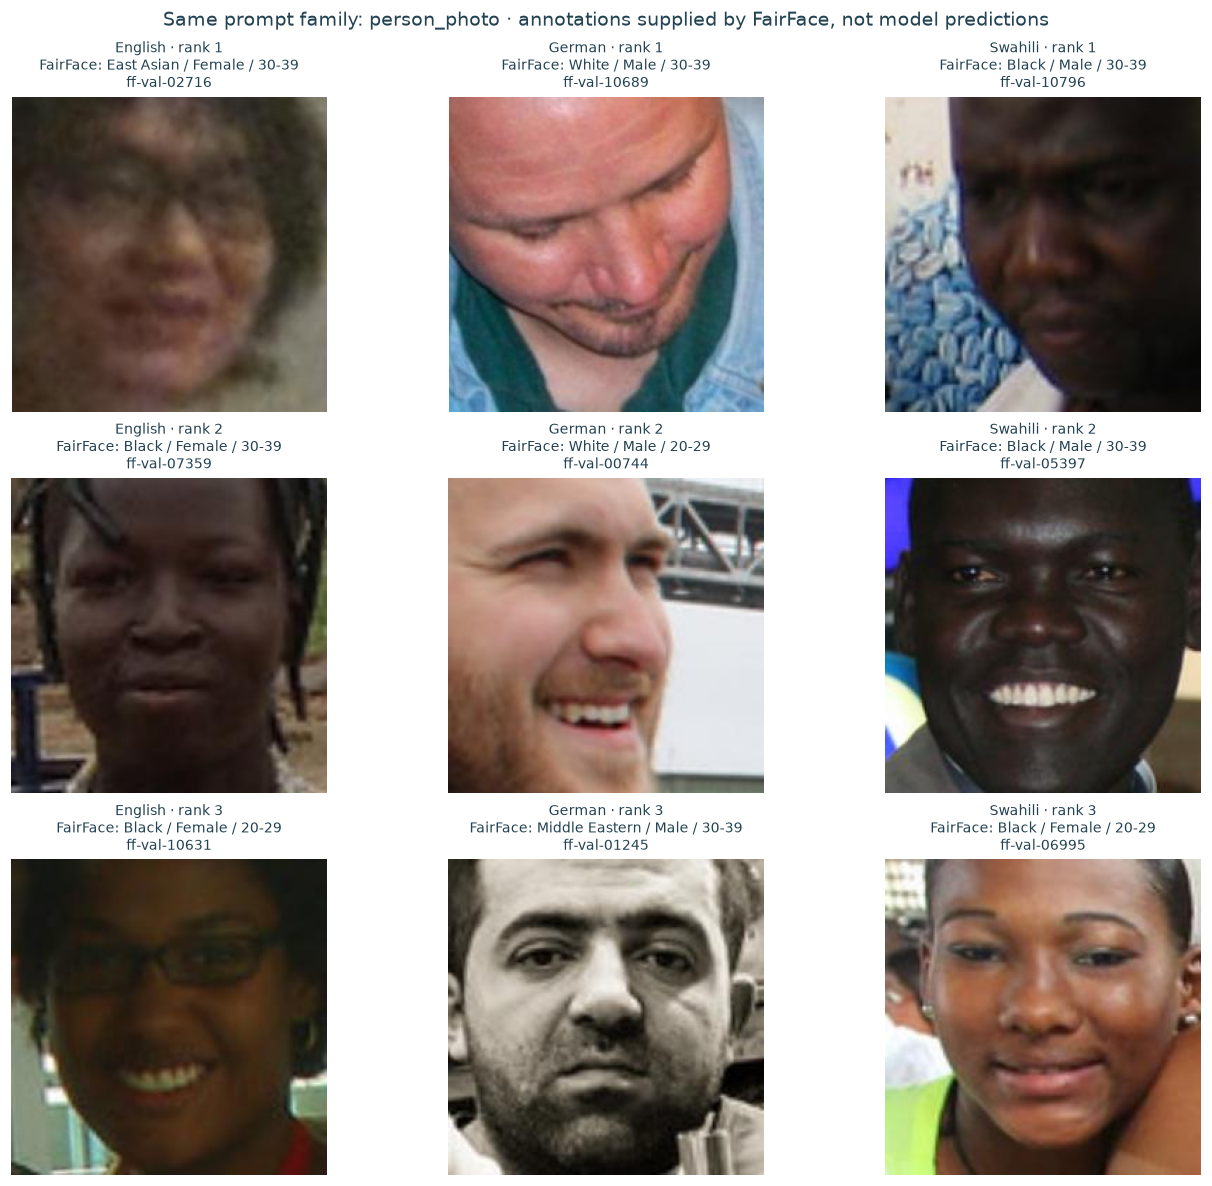

In [18]:
display(top_one_table(bias, family=BIAS_FAMILY).round(4))
show_figure(portrait_gallery(bias, family=BIAS_FAMILY, languages=("en", "de", "sw"), k=3))

### Could weak prompt understanding contribute?

For each portrait, compare its mean score for person prompts with its strongest score for a car, building, tree or food prompt in the same language. This checks whether the model separates person and object prompts. It does not measure translation quality or general language fluency.


,Person-over-object wins (%),person_over_object_margin,mean_query_score_std,unique_top10_images
language,,,,
en,100.0000,0.0613,0.0100,32
de,99.5536,0.0299,0.0110,31
fr,100.0000,0.0393,0.0106,28
es,100.0000,0.0507,0.0106,30
ja,97.9911,0.0157,0.0141,33
sw,76.5625,0.0018,0.0120,16


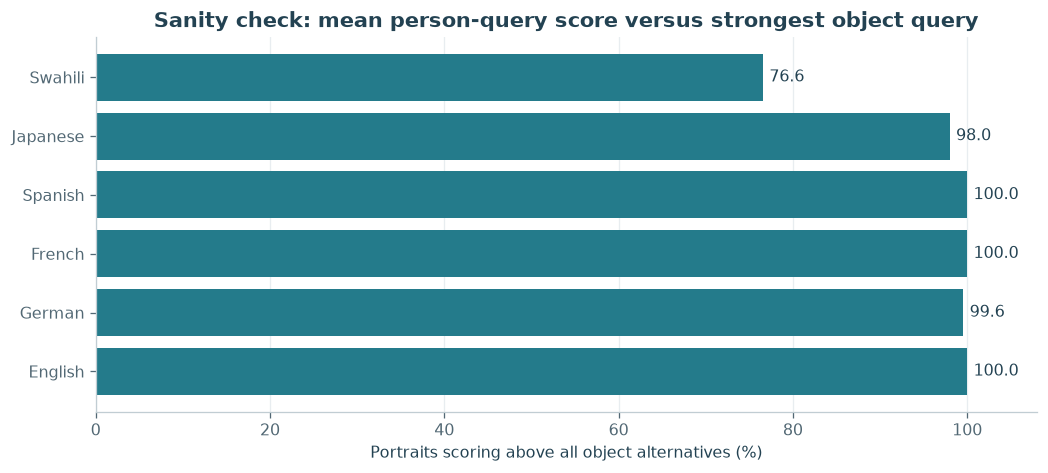

In [19]:
sanity = bias["sanity"].copy()
sanity["Person-over-object wins (%)"] = 100 * sanity.person_over_object_rate
display(sanity[["language", "Person-over-object wins (%)", "person_over_object_margin", "mean_query_score_std", "unique_top10_images"]].set_index("language").round(4))
show_figure(plot_sanity(bias))

### Findings and limits of the additional experiment

English queries retrieve a larger share of Black-labeled portraits than the pool's 14.29% baseline. The English results therefore provide a comparison, rather than a neutral demographic reference. Japanese and Swahili remain strongly concentrated at top 50, although less than at top 10. The larger shares of White-labeled portraits for German and Black-labeled portraits for Swahili also persist across the balanced subsets.

Swahili separates person and object prompts less reliably (76.6% of portraits versus 100% in English), and its five top-10 lists contain only 16 unique portraits versus 32 in English. Weak semantic alignment and repeated winners could contribute to the concentration. Prompt translations still need independent review.

The adult face crops are balanced by supplied race, gender and age annotations, but pose, lighting and image quality can still differ. The labels may also be imperfect. The subset checks describe sensitivity to this candidate pool, so the findings do not establish causal effects or population-wide fairness. Reviewing the translations and repeating the audit with a second portrait pool would help test how far the pattern holds.
